# 1. Contexto e objetivo

## Base escolhida: [Câncer de mama](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data/data)

O objetivo é desenvolver um modelo de classificação capaz de prever se um
tumor é benigno ou maligno com base em características extraídas de imagens
digitalizadas de massas mamárias.

A variável alvo é diagnosis, que identifica os registros como benignos (B) ou malignos (M). As entradas do modelo são 30 características numéricas relacionadas a medidas de tamanho, forma e textura extraídas das imagens. As colunas id e Unnamed: 32 serão excluídas por representarem, respectivamente, um identificador e uma coluna sem dados.


- B = benigno
- M = maligno


# 2. Carregamento e preparação dos dados


In [1]:
# INSTALAÇÃO DE DEPENDÊNCIAS
%pip install -q numpy pandas matplotlib seaborn missingno scikit-learn


Note: you may need to restart the kernel to use updated packages.


In [2]:
# IMPORTAÇÃO DAS BIBLIOTECAS QUE SERÃO UTILIZADAS
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import missingno as msno
import seaborn as sb
import math

from sklearn.base import clone
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)


### Inspeção inicial

Primeiro, vamos verificar a quantidade de registros e colunas, os tipos de dados e as principais estatísticas.


In [3]:
dados = pd.read_csv("database/data.csv")


In [4]:
len(dados.columns)


33

In [5]:
dados.shape


(569, 33)

In [6]:
dados.describe()


,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [7]:
dados.info()


<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Em `perimeter_mean`, a média é 91,97 e a mediana é 86,24. A média maior que a mediana é uma pista de que alguns valores altos puxam a média para cima. Vamos observar esse comportamento também no histograma.


### Limpeza dos dados

Vamos verificar os valores ausentes e remover a coluna `id`, que serve apenas para identificar os registros.


In [8]:
# IDENTIFICADO COLUNA DE ID, ELA NÃO  RELEVANTE PARA TREINAR O MODELO VAMOS TRATAR MAIS ABAIXO
dados.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


A coluna `Unnamed: 32` está completamente vazia, então vamos removê-la.


<Axes: >

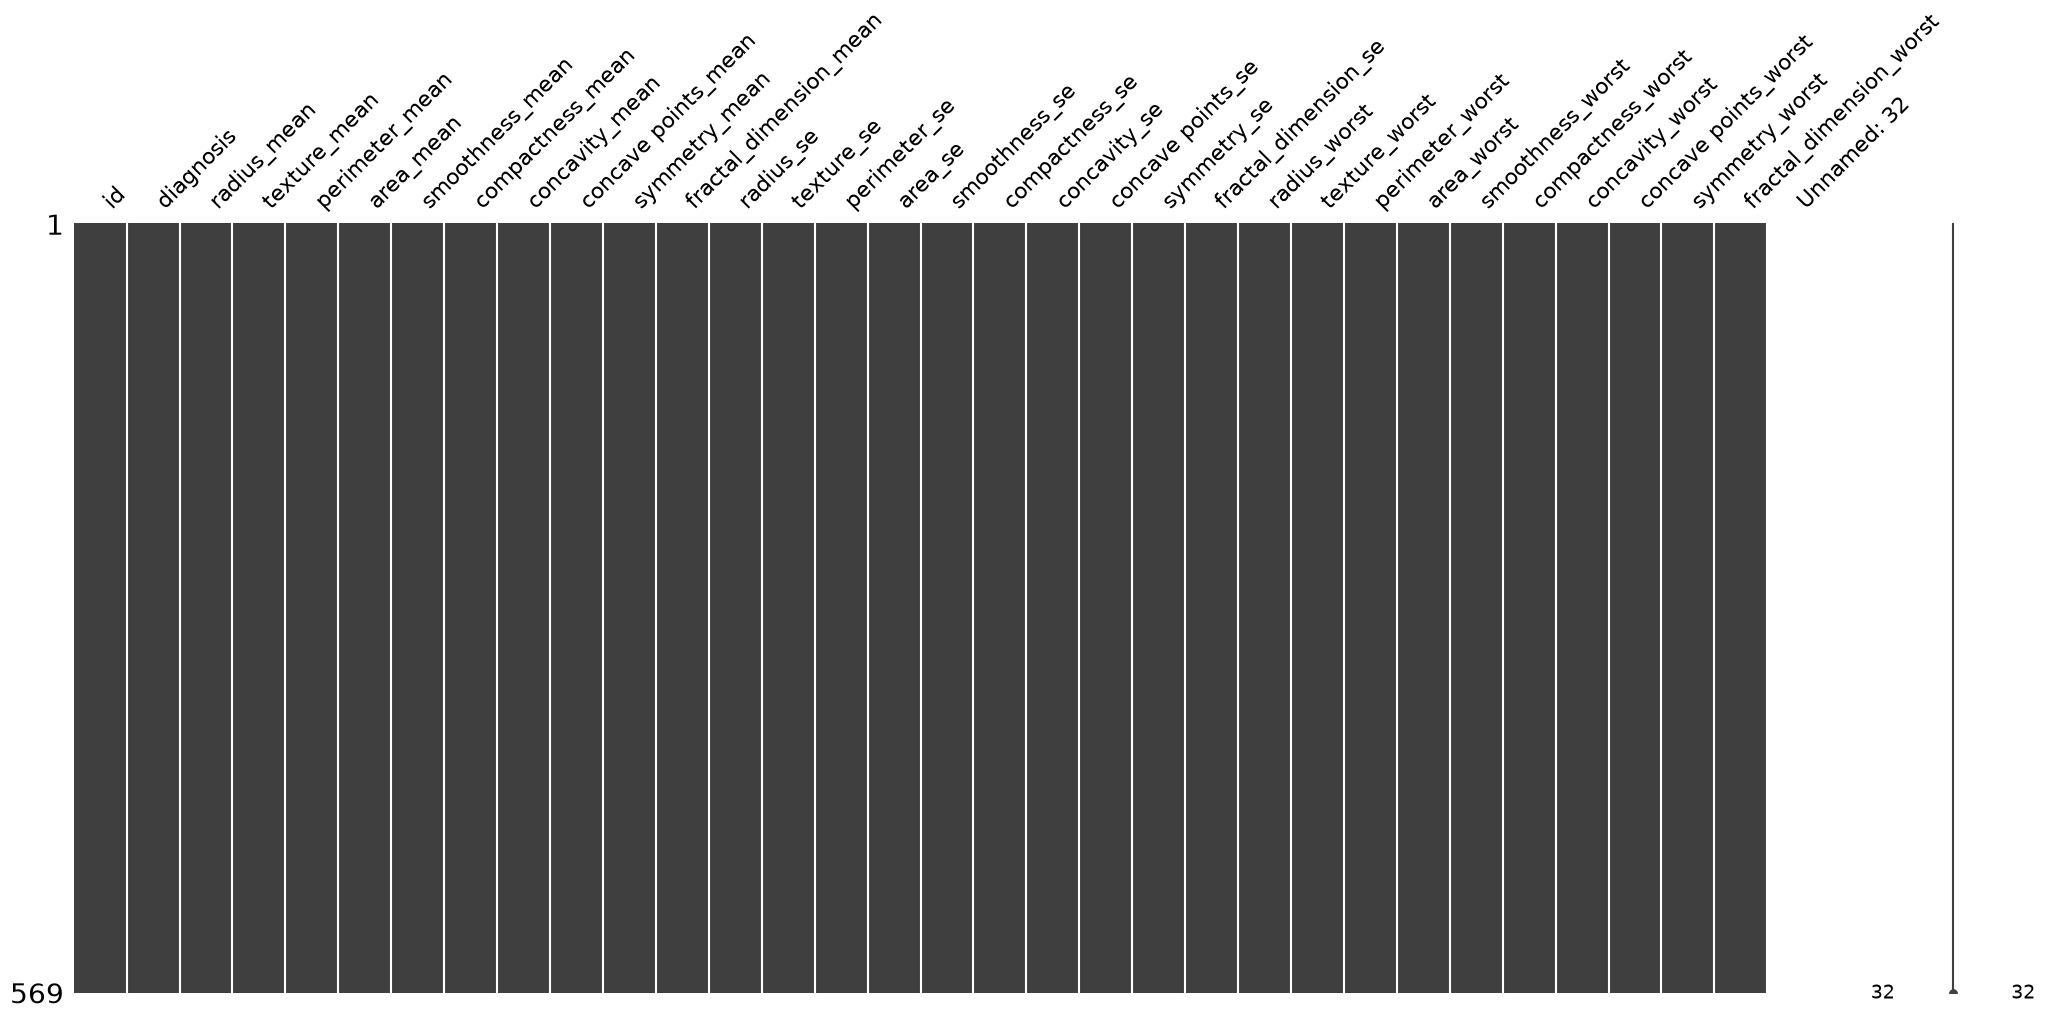

In [9]:
msno.matrix(dados)


In [10]:
if "Unnamed: 32" in dados.columns:
    dados.drop("Unnamed: 32", axis=1, inplace=True)

if "id" in dados.columns:
    dados.drop("id", axis=1, inplace=True)

dados.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [11]:
print("Duplicados:", dados.duplicated().sum())
print("Valores ausentes:", dados.isna().sum().sum())


Duplicados: 0
Valores ausentes: 0


Após a limpeza, a base ficou com 569 registros, 30 características numéricas e a coluna de diagnóstico. Não encontramos valores ausentes nem registros duplicados, então não foi necessário preencher ou excluir registros.


### Transformação do diagnóstico

Vamos usar o `LabelEncoder()` para representar o diagnóstico com números:

- Benigno (`B`) = 0.
- Maligno (`M`) = 1.

A coluna `diagnosis` é o resultado que queremos prever.


In [12]:
# OS DADOS ESTAO SENDO CLASSIFICADOS ENTRE MALIGNO E BENIGNO, TEREMOS QUE USAR UMA ESTRATEGIA
# DE TRANSFORMACAO NOS DADOS
# B = benigno
# M = maligno
set(dados['diagnosis'])

# B = 0
# M = 1


{'B', 'M'}

In [13]:
# APLICANDO A TECNICA DE LABEL ENCODE JÁ QUE TEMOS APENAS DE CATEGORIAS QUE PDOE SER REPRESENTADA
# POR 0 E 1 
label = LabelEncoder()

dados['diagnosis'] = label.fit_transform(dados['diagnosis'])


In [14]:
dados.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,1,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,1,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,1,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,1,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# 3. Análise exploratória dos dados


### Distribuição dos diagnósticos

A base possui 357 registros benignos (62,7%) e 212 malignos (37,3%). Há mais casos benignos, então vamos considerar essa proporção ao dividir os dados.


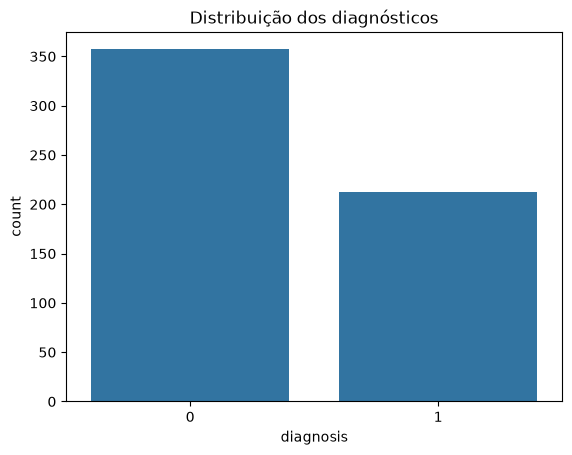

In [15]:
sb.countplot(data=dados, x="diagnosis")
plt.title("Distribuição dos diagnósticos")
plt.show()


### Distribuição dos valores e outliers

O boxplot ajuda a visualizar como os valores estão distribuídos. A caixa mostra os 50% centrais dos valores, a linha dentro dela indica a mediana e os pontos fora dos bigodes indicam possíveis outliers.


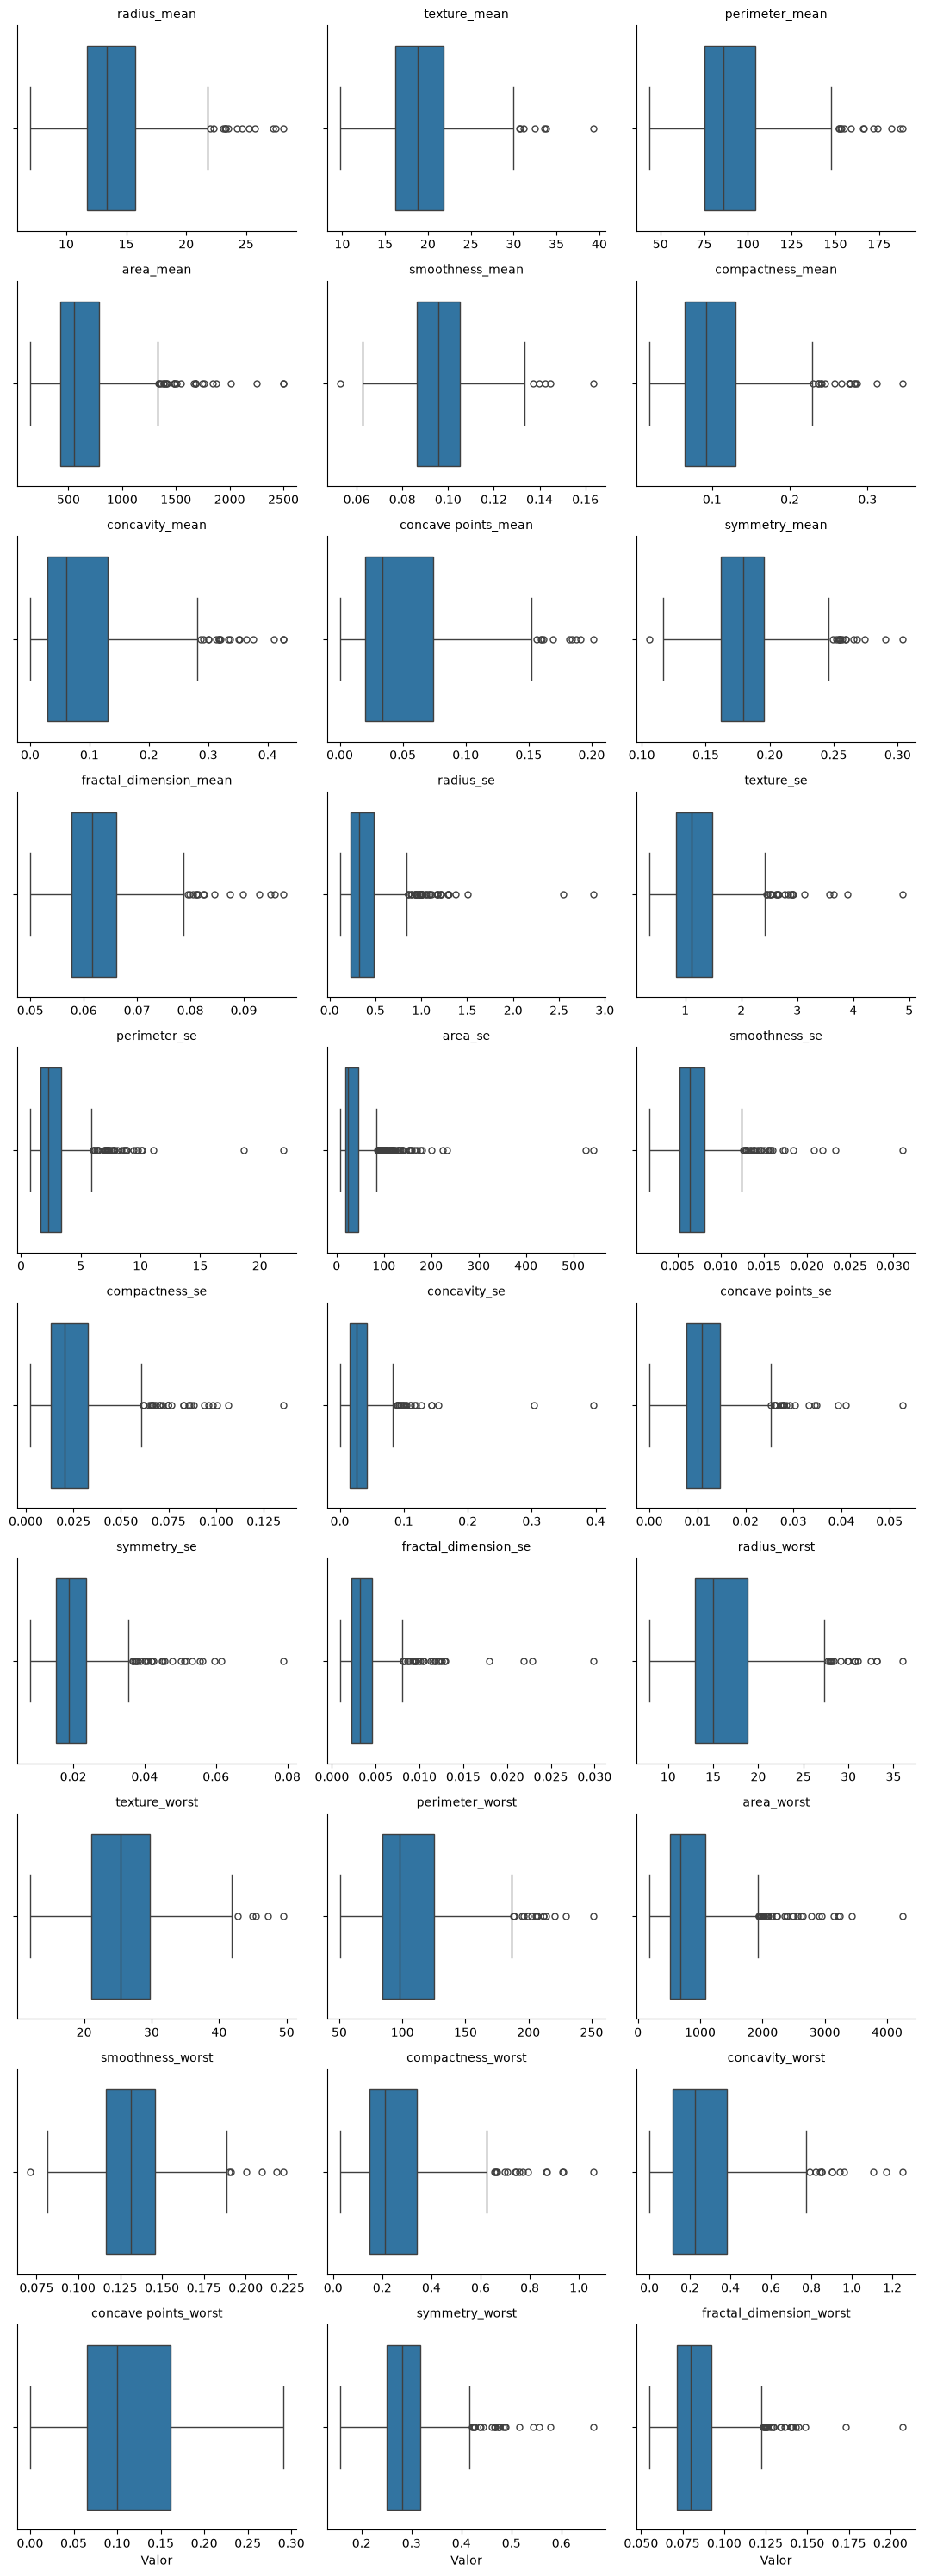

In [16]:
numericas = dados.drop(columns="diagnosis").select_dtypes(include="number")
dados_longos = numericas.melt(
    var_name="Coluna",
    value_name="Valor"
)

g = sb.catplot(
    data=dados_longos,
    x="Valor",
    col="Coluna",
    kind="box",
    col_wrap=3,
    sharex=False,
    sharey=False,
    height=3,
    aspect=1.2
)

g.set_titles("{col_name}")


Os boxplots mostram valores extremos em características como `perimeter_mean` e `area_mean`. Vamos mantê-los, pois um valor distante dos demais não significa necessariamente um erro e pode ajudar na classificação.


Os histogramas mostram quais faixas de valores são mais frequentes. Em `perimeter_mean`, por exemplo, há maior concentração aproximadamente entre 70 e 100 e poucos valores mais altos, formando uma cauda à direita.


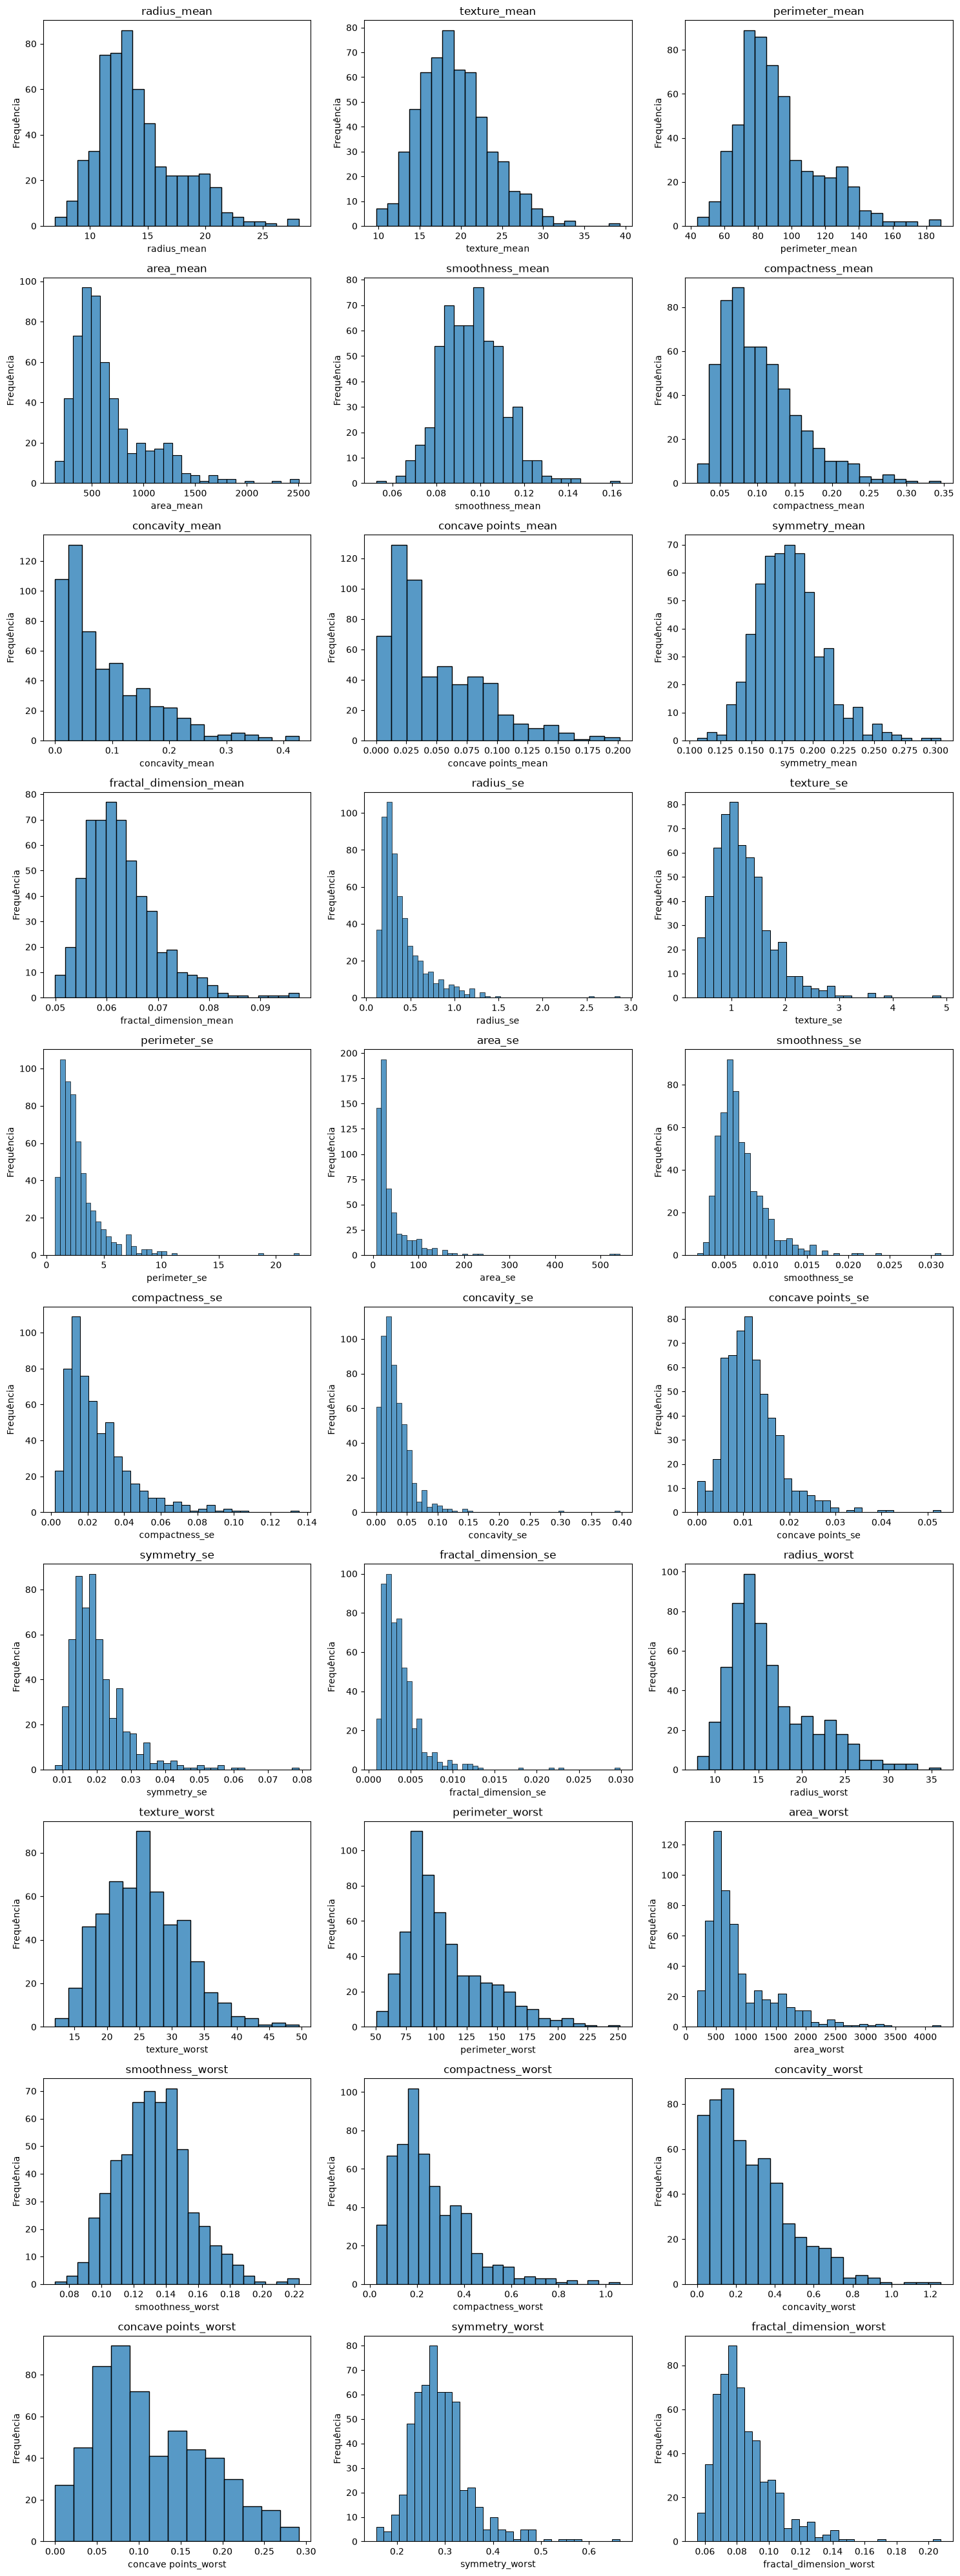

In [17]:
colunas = dados.drop(columns="diagnosis").select_dtypes(include="number").columns

por_linha = 3
linhas = math.ceil(len(colunas) / por_linha)

fig, axes = plt.subplots(
    linhas, por_linha,
    figsize=(15, 4 * linhas),
    squeeze=False
)

for ax, coluna in zip(axes.flat, colunas):
    sb.histplot(data=dados, x=coluna, ax=ax)
    ax.set_title(coluna)
    ax.set_ylabel("Frequência")

# Remove os espaços que sobraram na grade
for ax in list(axes.flat)[len(colunas):]:
    ax.remove()

plt.tight_layout()
plt.show()


Agora vamos comparar `perimeter_mean` entre benignos e malignos. Os casos malignos tendem a apresentar valores maiores, mas há uma faixa em que os dois grupos se misturam. Por isso, essa característica sozinha não separa todos os diagnósticos.

Como os grupos têm tamanhos diferentes, o histograma usa densidade para comparar onde os valores de cada grupo se concentram. Nesse formato, a área total das barras de cada grupo é igual a 1; a altura não é uma contagem de registros.


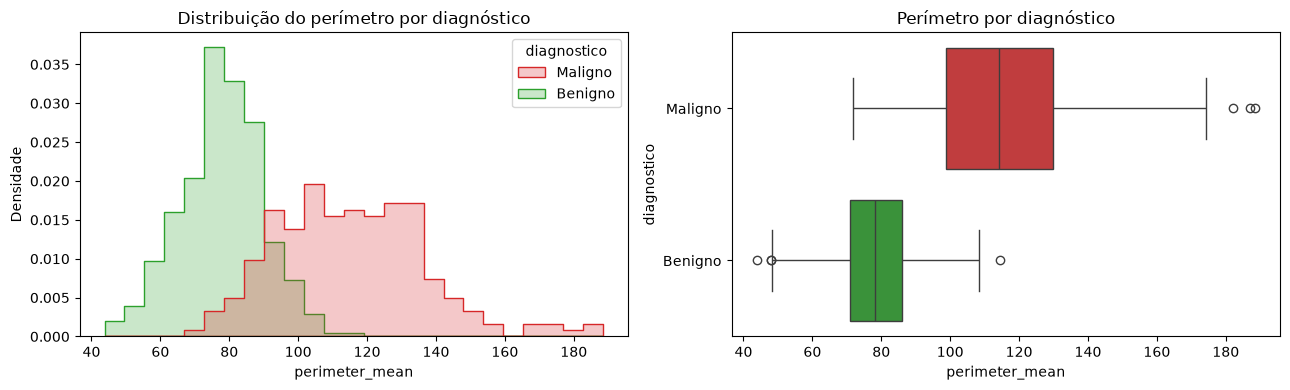

In [18]:
visualizacao = dados.assign(
    diagnostico=dados["diagnosis"].map({0: "Benigno", 1: "Maligno"})
)
paleta_diagnostico = {"Benigno": "#2ca02c", "Maligno": "#d62728"}

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sb.histplot(
    data=visualizacao,
    x="perimeter_mean",
    hue="diagnostico",
    palette=paleta_diagnostico,
    bins=25,
    stat="density",
    common_norm=False,
    element="step",
    ax=axes[0]
)
axes[0].set_title("Distribuição do perímetro por diagnóstico")
axes[0].set_ylabel("Densidade")

sb.boxplot(
    data=visualizacao,
    x="perimeter_mean",
    y="diagnostico",
    hue="diagnostico",
    palette=paleta_diagnostico,
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Perímetro por diagnóstico")

plt.tight_layout()
plt.show()


As maiores correlações com o diagnóstico aparecem em `concave points_worst`, `perimeter_worst`, `concave points_mean` e `radius_worst`, próximas de 0,78. Como maligno foi representado por 1, a correlação positiva indica que valores maiores dessas características estão associados aos casos malignos nesta base.

Raio, perímetro e área também têm correlações altas entre si, mostrando que algumas colunas trazem informações parecidas. Essas relações ajudam a entender os dados, mas não significam que uma característica determine o diagnóstico.


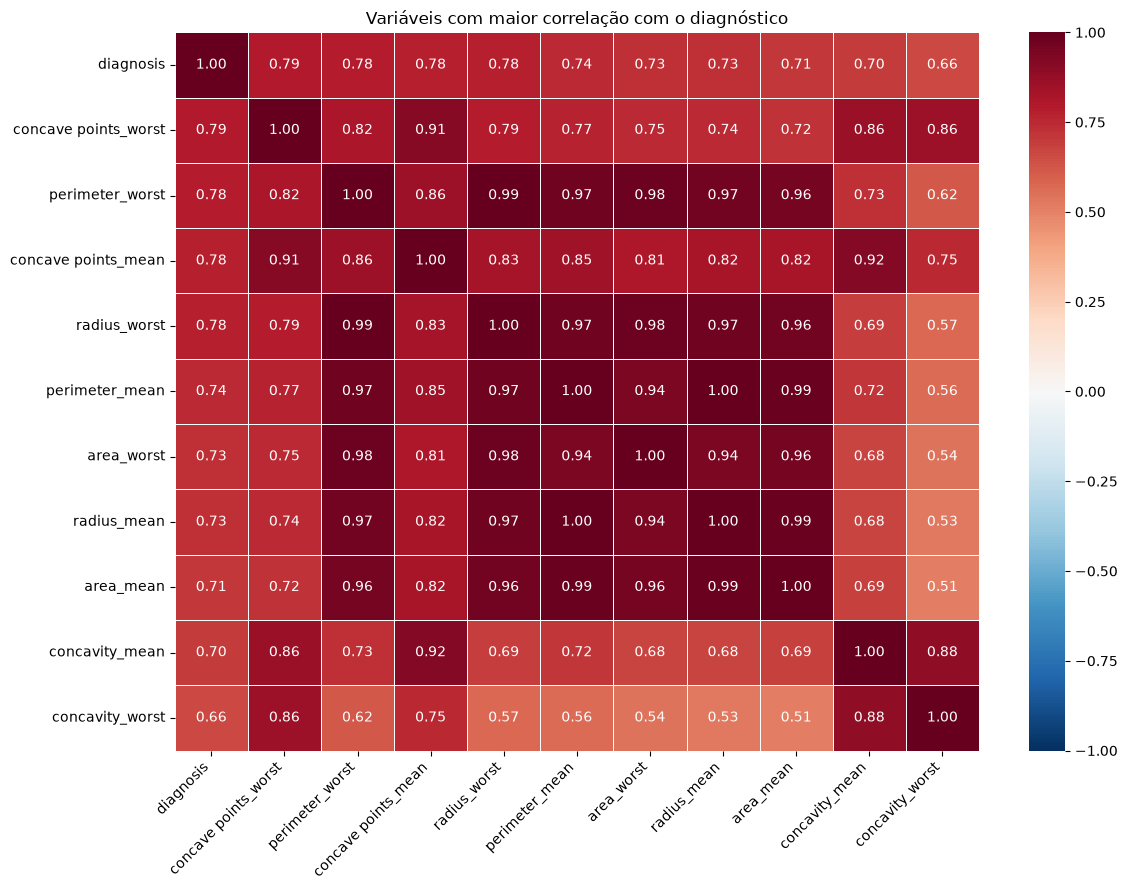

In [19]:
# Calcula as correlações
correlacoes = dados.corr(numeric_only=True)

# Seleciona as 10 maiores correlações com o diagnóstico
mais_correlacionadas = (
    correlacoes["diagnosis"]
    .drop("diagnosis")
    .dropna()
    .abs()
    .nlargest(10)
    .index
)

# Inclui o diagnóstico na matriz reduzida
colunas = ["diagnosis"] + mais_correlacionadas.tolist()
matriz_menor = correlacoes.loc[colunas, colunas]

# Desenha o gráfico
fig, ax = plt.subplots(figsize=(12, 9))

sb.heatmap(
    matriz_menor,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    linewidths=0.5,
    ax=ax
)

ax.set_title("Variáveis com maior correlação com o diagnóstico")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


Para facilitar a leitura do `pairplot`, vamos usar as três características mais correlacionadas com o diagnóstico. As cores permitem comparar os grupos e observar onde eles se separam ou se misturam.


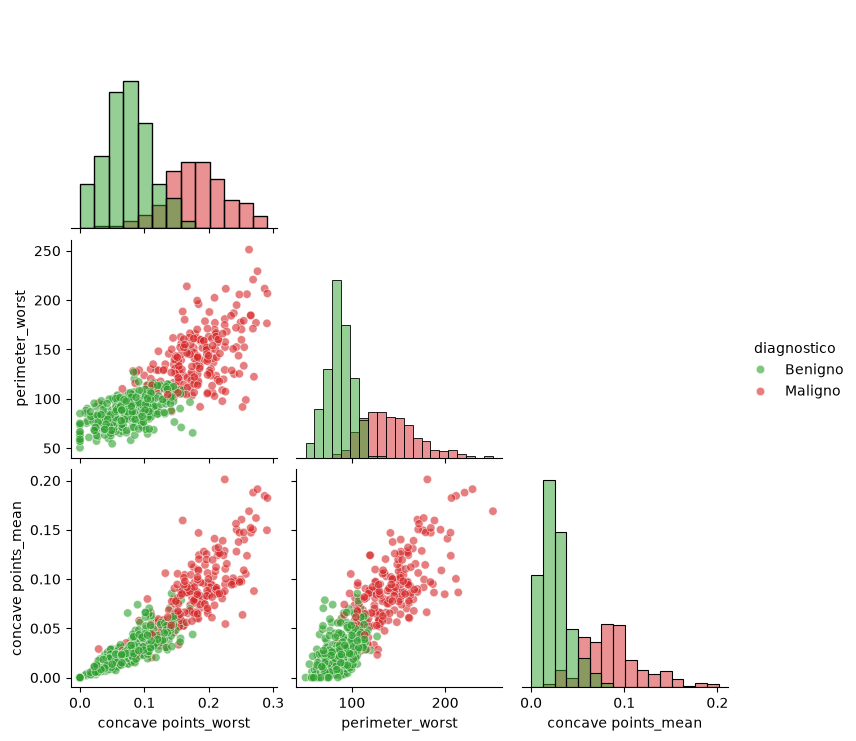

In [20]:
variaveis_pairplot = [
    "concave points_worst",
    "perimeter_worst",
    "concave points_mean"
]

sb.pairplot(
    data=visualizacao,
    vars=variaveis_pairplot,
    hue="diagnostico",
    hue_order=["Benigno", "Maligno"],
    palette=paleta_diagnostico,
    corner=True,
    diag_kind="hist",
    plot_kws={"alpha": 0.6}
)
plt.show()


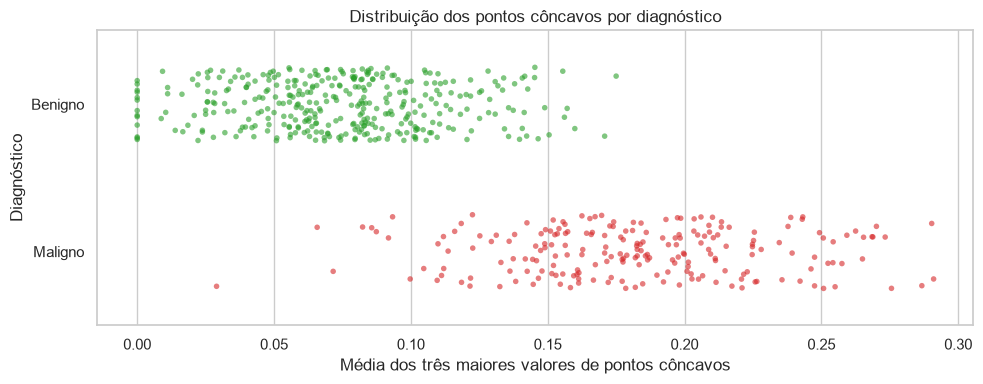

In [21]:
sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

ax = sb.stripplot(
    data=visualizacao,
    x="concave points_worst",
    y="diagnostico",
    order=["Benigno", "Maligno"],
    hue="diagnostico",
    palette=paleta_diagnostico,
    jitter=0.25,
    alpha=0.6,
    size=4,
    legend=False
)

ax.set(
    xlabel="Média dos três maiores valores de pontos côncavos",
    ylabel="Diagnóstico",
    title="Distribuição dos pontos côncavos por diagnóstico"
)

plt.tight_layout()
plt.show()


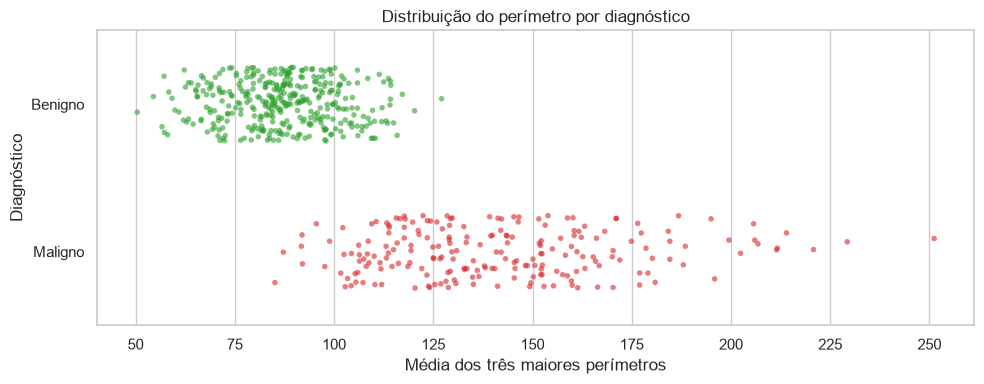

In [22]:
visualizacao = dados.assign(
    diagnostico=dados["diagnosis"].map({0: "Benigno", 1: "Maligno"})
)

sb.set_theme(style="whitegrid")
plt.figure(figsize=(10, 4))

ax = sb.stripplot(
    data=visualizacao,
    x="perimeter_worst",
    y="diagnostico",
    order=["Benigno", "Maligno"],
    hue="diagnostico",
    palette=paleta_diagnostico,
    jitter=0.25,
    alpha=0.6,
    size=4,
    legend=False
)

ax.set(
    xlabel="Média dos três maiores perímetros",
    ylabel="Diagnóstico",
    title="Distribuição do perímetro por diagnóstico"
)

plt.tight_layout()
plt.show()


# 4. Preparação das variáveis

Vamos separar as características em `x` e o diagnóstico em `y`. Assim, o modelo recebe as medidas e aprende a prever o diagnóstico.


In [23]:
x = dados.drop(columns="diagnosis")
y = dados["diagnosis"]


# 5. Divisão final dos dados

### Efeito do stratify

Primeiro, vamos comparar uma divisão sem `stratify` com outra usando esse parâmetro. O `stratify` ajuda a manter a proporção de benignos e malignos parecida com a da base original, sem deixar as classes necessariamente iguais.

Os conjuntos criados nesta comparação não são usados para treinar nem para avaliar os modelos.


In [24]:
# Demonstração sem stratify. Estes conjuntos não treinam os modelos.
x_demo_treino, x_demo_teste, y_demo_treino, y_demo_teste = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)


Sem estratificação, a diferença na proporção de benignos entre treino e teste foi de aproximadamente 0,58 ponto percentual. As proporções já ficaram próximas nesse sorteio. Vamos comparar com o uso de `stratify`.


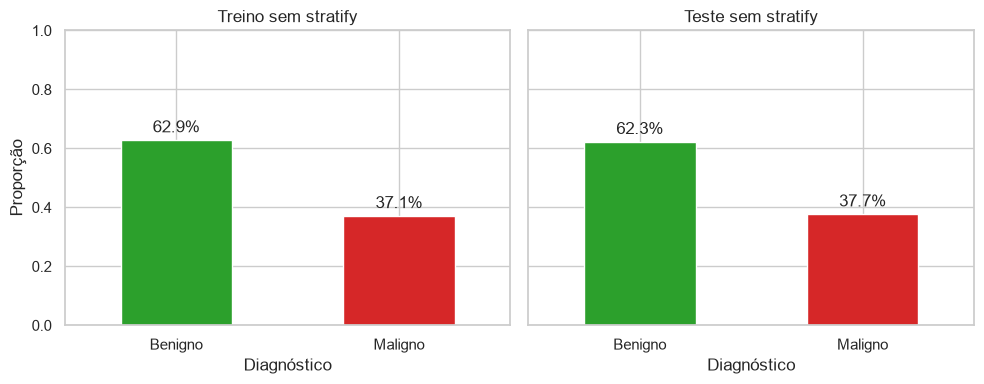

In [25]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharey=True
)

ordem = [0, 1]
cores = ["#2ca02c", "#d62728"]

y_demo_treino.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar",
    color=cores,
    ax=axes[0]
)

y_demo_teste.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar",
    color=cores,
    ax=axes[1]
)

axes[0].set_title("Treino sem stratify")
axes[1].set_title("Teste sem stratify")

for ax in axes:
    ax.set_xticklabels(["Benigno", "Maligno"], rotation=0)
    ax.set_xlabel("Diagnóstico")
    ax.set_ylim(0, 1)

    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[f"{barra.get_height():.1%}" for barra in container],
            padding=3
        )

axes[0].set_ylabel("Proporção")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [26]:
print("Treino (%)")
print(y_demo_treino.value_counts(normalize=True).sort_index() * 100)
print("\nTeste (%)")
print(y_demo_teste.value_counts(normalize=True).sort_index() * 100)


Treino (%)
diagnosis
0    62.857143
1    37.142857
Name: proportion, dtype: float64

Teste (%)
diagnosis
0    62.280702
1    37.719298
Name: proportion, dtype: float64


In [27]:
# Demonstração com stratify. Estes conjuntos não treinam os modelos.
x_demo_treino, x_demo_teste, y_demo_treino, y_demo_teste = train_test_split(
    x,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)


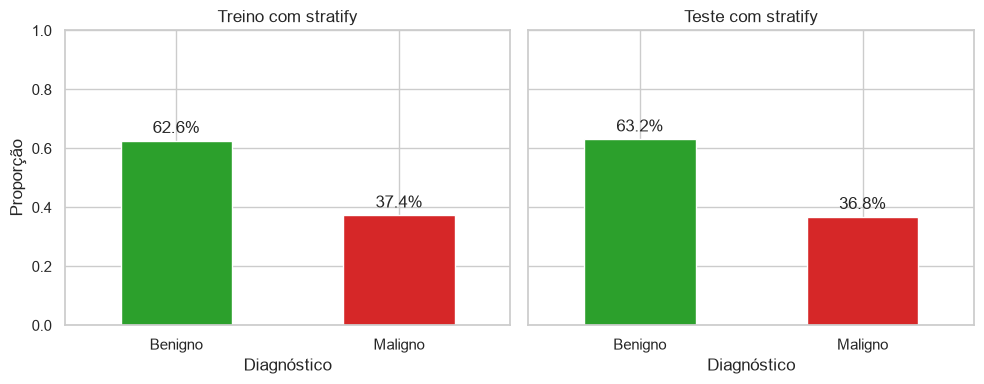

In [28]:
fig, axes = plt.subplots(
    1,
    2,
    figsize=(10, 4),
    sharey=True
)

ordem = [0, 1]
cores = ["#2ca02c", "#d62728"]

y_demo_treino.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar",
    color=cores,
    ax=axes[0]
)

y_demo_teste.value_counts(normalize=True).reindex(ordem).plot(
    kind="bar",
    color=cores,
    ax=axes[1]
)

axes[0].set_title("Treino com stratify")
axes[1].set_title("Teste com stratify")

for ax in axes:
    ax.set_xticklabels(["Benigno", "Maligno"], rotation=0)
    ax.set_xlabel("Diagnóstico")
    ax.set_ylim(0, 1)

    for container in ax.containers:
        ax.bar_label(
            container,
            labels=[f"{barra.get_height():.1%}" for barra in container],
            padding=3
        )

axes[0].set_ylabel("Proporção")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()


In [29]:
print("Treino (%)")
print(y_demo_treino.value_counts(normalize=True).sort_index() * 100)
print("\nTeste (%)")
print(y_demo_teste.value_counts(normalize=True).sort_index() * 100)


Treino (%)
diagnosis
0    62.637363
1    37.362637
Name: proportion, dtype: float64

Teste (%)
diagnosis
0    63.157895
1    36.842105
Name: proportion, dtype: float64


Com `stratify`, a diferença entre treino e teste caiu de 0,58 para 0,52 ponto percentual. A melhora foi pequena porque o sorteio anterior já tinha produzido proporções próximas. Como o teste tem 114 registros, um único registro representa cerca de 0,88 ponto percentual, o que impede um ajuste exato das proporções.


### Conjuntos de treino, validação e teste

As divisões anteriores serviram para demonstrar o efeito do `stratify`. Esta é a única divisão usada para treinar e avaliar os modelos:

- Treino: 341 registros, cerca de 60%, para ensinar os modelos.
- Validação: 114 registros, cerca de 20%, para comparar as versões.
- Teste: 114 registros, cerca de 20%, para a avaliação final.

O conjunto de teste permanece reservado até a avaliação final.


In [30]:
# Divisão final: aproximadamente 60% treino, 20% validação e 20% teste.
x_desenvolvimento, x_test, y_desenvolvimento, y_test = train_test_split(
    x, y, test_size=0.2, stratify=y, random_state=42
)
x_train, x_val, y_train, y_val = train_test_split(
    x_desenvolvimento, y_desenvolvimento,
    test_size=0.25, stratify=y_desenvolvimento, random_state=42
)

print("Treino:", x_train.shape)
print("Validação:", x_val.shape)
print("Teste:", x_test.shape)


Treino: (341, 30)
Validação: (114, 30)
Teste: (114, 30)


# 6. Modelos de classificação


## Pipeline de regressão logística

Escolhemos a regressão logística por ser um modelo de classificação adequado a problemas com duas classes, como benigno e maligno.

O pipeline reúne a padronização e o modelo. O `StandardScaler` coloca as características em escalas comparáveis, já que área, perímetro e outras medidas têm valores muito diferentes. Ele calcula a média e o desvio padrão apenas no treino e usa esses mesmos valores nos outros conjuntos.


In [31]:
modelo_regressao = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])


## Pipeline do KNN

O KNN final usa `StandardScaler` e `KNeighborsClassifier` com `n_neighbors=5`.


In [32]:
modelo_knn = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", KNeighborsClassifier(
        n_neighbors=5
    ))
])


# 7. Validação e escolha do K

Cada valor de K é treinado com o conjunto de treino e avaliado somente no conjunto de validação.


In [33]:
for k in [3, 5, 7, 9, 11]:
    modelo_knn_k = Pipeline([
        ("padronizacao", StandardScaler()),
        ("modelo", KNeighborsClassifier(n_neighbors=k))
    ])

    modelo_knn_k.fit(x_train, y_train)

    y_val_pred = modelo_knn_k.predict(x_val)

    print(
        f"K={k} | "
        f"Accuracy={accuracy_score(y_val, y_val_pred):.4f} | "
        f"Recall={recall_score(y_val, y_val_pred, pos_label=1):.4f} | "
        f"F1={f1_score(y_val, y_val_pred, pos_label=1):.4f}"
    )


K=3 | Accuracy=0.9649 | Recall=0.9302 | F1=0.9524
K=5 | Accuracy=0.9737 | Recall=0.9302 | F1=0.9639
K=7 | Accuracy=0.9737 | Recall=0.9302 | F1=0.9639
K=9 | Accuracy=0.9737 | Recall=0.9302 | F1=0.9639
K=11 | Accuracy=0.9737 | Recall=0.9302 | F1=0.9639


K=5, K=7, K=9 e K=11 empataram na validação, com acurácia e F1 maiores que K=3 e o mesmo recall. O modelo final de KNN permanece com K=5.


### Experimento com dez características

Vamos verificar se o modelo mantém o desempenho usando apenas as dez características mais correlacionadas com o diagnóstico. Essa seleção é calculada somente no treino, sem usar os resultados da validação ou do teste.

Usamos o valor absoluto da correlação para considerar tanto relações positivas quanto negativas. Criamos outro pipeline para manter o modelo com 30 características e comparar os dois.


In [34]:
top10 = (
    x_train.corrwith(y_train)
    .abs()
    .nlargest(10)
    .index
)


In [35]:
# Comparação na validação, sem usar o conjunto de teste.
modelo_regressao_30 = clone(modelo_regressao)
modelo_regressao_30.fit(x_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('padronizacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [36]:
# Avaliação na validação; teste reservado para a avaliação final.
predito = modelo_regressao_30.predict(x_val)

print("Acurácia:", accuracy_score(y_val, predito))
print("\nMatriz de confusão:")
print(confusion_matrix(y_val, predito))
print("\nRelatório de classificação:")
print(classification_report(y_val, predito, target_names=["Benigno", "Maligno"]))


Acurácia: 0.9736842105263158

Matriz de confusão:
[[69  2]
 [ 1 42]]

Relatório de classificação:
              precision    recall  f1-score   support

     Benigno       0.99      0.97      0.98        71
     Maligno       0.95      0.98      0.97        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



In [37]:
# Pipeline independente para preservar o modelo com 30 características.
modelo_regressao_top10 = clone(modelo_regressao)
modelo_regressao_top10.fit(x_train[top10], y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('padronizacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['concave points_worst','perimeter_worst','concave points_mean',..., 'area_mean','concavity_mean','concavity_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [38]:
# Avaliação na validação; teste reservado para a avaliação final.
predito_top10 = modelo_regressao_top10.predict(x_val[top10])

print("Acurácia:", accuracy_score(y_val, predito_top10))
print("\nMatriz de confusão:")
print(confusion_matrix(y_val, predito_top10))
print("\nRelatório de classificação:")
print(classification_report(y_val, predito_top10, target_names=["Benigno", "Maligno"]))


Acurácia: 0.9736842105263158

Matriz de confusão:
[[70  1]
 [ 2 41]]

Relatório de classificação:
              precision    recall  f1-score   support

     Benigno       0.97      0.99      0.98        71
     Maligno       0.98      0.95      0.96        43

    accuracy                           0.97       114
   macro avg       0.97      0.97      0.97       114
weighted avg       0.97      0.97      0.97       114



### Comparação dos erros na validação

Considerando maligno como classe positiva:

- Falso positivo: um registro benigno classificado como maligno.
- Falso negativo: um registro maligno classificado como benigno.

Na matriz de confusão, as linhas mostram o diagnóstico real e as colunas mostram a previsão. Com a ordem benigno e maligno, ela fica assim: `[[VN, FP], [FN, VP]]`.

A acurácia mostra a proporção total de acertos. O recall dos malignos mostra quantos casos malignos o modelo conseguiu identificar. A precisão mostra quantas previsões de malignidade estavam corretas, e o F1 combina precisão e recall. Vamos observar essas métricas porque a mesma acurácia pode esconder tipos diferentes de erro.


In [39]:
resultados = []

for nome, modelo, entradas in [
    ("30 características", modelo_regressao_30, x_val),
    ("10 características", modelo_regressao_top10, x_val[top10])
]:
    previsoes = modelo.predict(entradas)
    vn, fp, fn, vp = confusion_matrix(y_val, previsoes, labels=[0, 1]).ravel()
    resultados.append({
        "Modelo": nome,
        "Verdadeiros negativos": vn,
        "Falsos positivos": fp,
        "Falsos negativos": fn,
        "Verdadeiros positivos": vp,
        "Acurácia (%)": 100 * (vn + vp) / len(y_val),
        "Recall maligno (%)": 100 * vp / (vp + fn)
    })

comparacao = pd.DataFrame(resultados).set_index("Modelo")
comparacao.round(2)


,Verdadeiros negativos,Falsos positivos,Falsos negativos,Verdadeiros positivos,Acurácia (%),Recall maligno (%)
Modelo,,,,,,
30 características,69,2,1,42,97.37,97.67
10 características,70,1,2,41,97.37,95.35


### Conclusão da comparação

Os dois modelos acertaram 111 dos 114 registros da validação, com acurácia de 97,37%. Com 30 características, ocorreram 2 falsos positivos e 1 falso negativo. Com 10 características, ocorreu 1 falso positivo e 2 falsos negativos.

Embora a acurácia seja igual, o modelo completo identificou mais casos malignos, com recall de 97,67%, contra 95,35% do modelo reduzido. Assim, nesta comparação, manter as 30 características foi mais adequado ao objetivo de identificar os casos malignos.


# 8. Avaliação final no conjunto de teste

Os modelos finais são treinados com o conjunto de treino. As previsões e as métricas desta seção usam somente o conjunto de teste.


In [40]:
modelo_regressao.fit(x_train, y_train)
modelo_knn.fit(x_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('padronizacao', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['radius_mean','texture_mean','perimeter_mean',...,'concave points_worst', 'symmetry_worst','fractal_dimension_worst']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


In [41]:
dados_padronizados = pd.DataFrame(
    modelo_regressao.named_steps["padronizacao"].transform(x_train),
    columns=x_train.columns,
    index=x_train.index
)

dados_padronizados.head()


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
194,0.193816,0.868298,0.331466,0.032564,0.613748,1.783766,1.045534,1.032611,-0.251128,0.620637,...,-0.052887,0.315841,0.318314,-0.179176,-0.009969,1.342242,0.885112,0.893857,0.151890,0.201773
46,-1.660366,-0.594469,-1.630154,-1.273254,-0.677435,-0.820919,-0.904895,-1.075643,-0.134430,0.371642,...,-1.497605,-0.650646,-1.471377,-1.105073,-0.090384,-0.756877,-0.968367,-1.338773,0.316997,-0.554997
332,-0.818973,0.099025,-0.815129,-0.757602,0.683921,-0.663777,-1.042776,-1.033256,0.489177,-0.328197,...,-0.885285,-0.016285,-0.898057,-0.774139,0.447129,-1.005697,-1.231826,-1.421058,0.611043,-1.074545
76,-0.176242,-1.949308,-0.171731,-0.279497,2.347021,0.030016,-0.234252,0.441833,2.177655,0.574963,...,-0.458935,-2.223263,-0.476456,-0.485021,0.561404,-0.742845,-0.889543,-0.603520,-0.304117,-0.682688
124,-0.220760,-0.697804,-0.244652,-0.295351,-1.719504,-0.561146,-0.080191,-0.513793,-1.399877,-0.630233,...,-0.422391,-0.519456,-0.458075,-0.439622,-1.241595,-0.008057,0.276472,-0.365015,-1.345073,-0.426721


In [42]:
y_test_pred_regressao = modelo_regressao.predict(x_test)
y_test_pred_knn = modelo_knn.predict(x_test)


In [43]:
print("Regressão Logística")
print("Accuracy:", accuracy_score(y_test, y_test_pred_regressao))
print("Recall:", recall_score(y_test, y_test_pred_regressao, pos_label=1))
print("F1-score:", f1_score(y_test, y_test_pred_regressao, pos_label=1))


Regressão Logística
Accuracy: 0.9736842105263158
Recall: 0.9523809523809523
F1-score: 0.963855421686747


In [44]:
print("KNN (K=5)")
print("Accuracy:", accuracy_score(y_test, y_test_pred_knn))
print("Recall:", recall_score(y_test, y_test_pred_knn, pos_label=1))
print("F1-score:", f1_score(y_test, y_test_pred_knn, pos_label=1))


KNN (K=5)
Accuracy: 0.9473684210526315
Recall: 0.8809523809523809
F1-score: 0.925


# 9. Matrizes de confusão


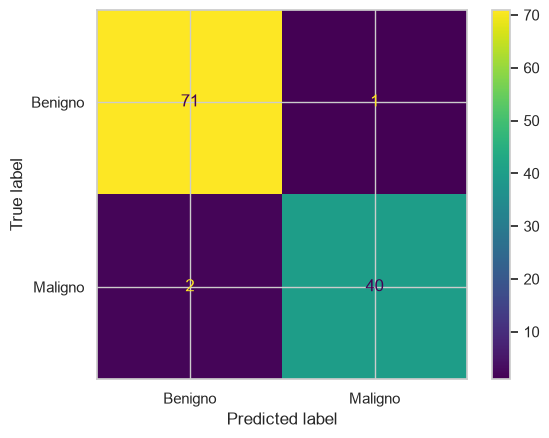

In [45]:
matriz_regressao = confusion_matrix(
    y_test,
    y_test_pred_regressao,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_regressao,
    display_labels=["Benigno", "Maligno"]
).plot()


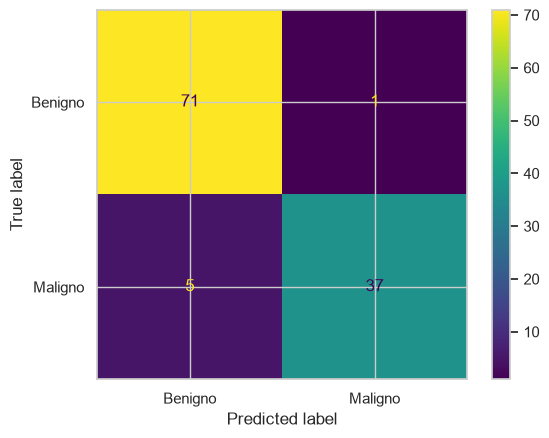

In [46]:
matriz_knn = confusion_matrix(
    y_test,
    y_test_pred_knn,
    labels=[0, 1]
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz_knn,
    display_labels=["Benigno", "Maligno"]
).plot()


# 10. Comparação dos modelos


In [47]:
comparacao_modelos = {
    "Modelo": ["Regressão Logística", "KNN"],
    "Accuracy": [
        accuracy_score(y_test, y_test_pred_regressao),
        accuracy_score(y_test, y_test_pred_knn)
    ],
    "Recall": [
        recall_score(y_test, y_test_pred_regressao, pos_label=1),
        recall_score(y_test, y_test_pred_knn, pos_label=1)
    ],
    "F1-score": [
        f1_score(y_test, y_test_pred_regressao, pos_label=1),
        f1_score(y_test, y_test_pred_knn, pos_label=1)
    ]
}

comparacao_modelos


{'Modelo': ['Regressão Logística', 'KNN'],
 'Accuracy': [0.9736842105263158, 0.9473684210526315],
 'Recall': [0.9523809523809523, 0.8809523809523809],
 'F1-score': [0.963855421686747, 0.925]}

### Desempenho no conjunto de teste

Os dois modelos foram avaliados utilizando o mesmo conjunto de teste, permitindo uma comparação direta entre seus desempenhos.

| Modelo | Accuracy | Recall | F1-score |
|---|---:|---:|---:|
| **Regressão Logística** | **97,37%** | **95,24%** | **96,39%** |
| **KNN (K=5)** | 94,74% | 88,10% | 92,50% |

---

### Análise dos resultados

A **Regressão Logística apresentou o melhor desempenho nas três métricas avaliadas**.

Em relação ao KNN, apresentou:

- maior Accuracy: **97,37% contra 94,74%**;
- maior Recall para a classe maligna: **95,24% contra 88,10%**;
- maior F1-score: **96,39% contra 92,50%**.

A diferença é especialmente relevante no **Recall da classe maligna**, pois essa métrica representa a capacidade do modelo de identificar corretamente os casos malignos.

---

### Análise dos erros

A matriz de confusão apresentou os seguintes resultados:

| Modelo | Benignos corretamente classificados | Malignos corretamente classificados | Falsos positivos | Falsos negativos |
|---|---:|---:|---:|---:|
| **Regressão Logística** | 71 | 40 | 1 | **2** |
| **KNN (K=5)** | 71 | 37 | 1 | **5** |

O principal ponto de atenção são os **falsos negativos**, ou seja, casos realmente malignos classificados pelo modelo como benignos.

A Regressão Logística apresentou **2 falsos negativos**, enquanto o KNN apresentou **5**.

Portanto, nesse conjunto de teste, a Regressão Logística demonstrou maior capacidade de identificar corretamente os casos malignos.

---

### Critério de escolha

Para este problema, o **Recall da classe maligna** possui importância especial. Um falso negativo representa um caso maligno classificado como benigno, situação que deve receber atenção na análise de desempenho do modelo.

Considerando conjuntamente **Accuracy, Recall, F1-score e a quantidade de falsos negativos**, a **Regressão Logística foi o modelo com melhor desempenho neste experimento**.

> **Conclusão:** entre os dois modelos avaliados, a Regressão Logística apresentou o resultado mais consistente para o conjunto de teste utilizado.


# 11. Interpretação das características


In [48]:
coeficientes = modelo_regressao.named_steps["modelo"].coef_[0]

importancia_regressao = pd.DataFrame({
    "Caracteristica": x.columns,
    "Coeficiente": coeficientes,
    "Importancia_absoluta": abs(coeficientes)
}).sort_values(
    "Importancia_absoluta",
    ascending=False
)

importancia_regressao.head(10)


,Caracteristica,Coeficiente,Importancia_absoluta
21,texture_worst,1.355329,1.355329
7,concave points_mean,1.104290,1.104290
10,radius_se,1.025939,1.025939
28,symmetry_worst,0.951861,0.951861
20,radius_worst,0.813413,0.813413
23,area_worst,0.794784,0.794784
13,area_se,0.782246,0.782246
26,concavity_worst,0.768948,0.768948
6,concavity_mean,0.762093,0.762093
15,compactness_se,-0.759123,0.759123


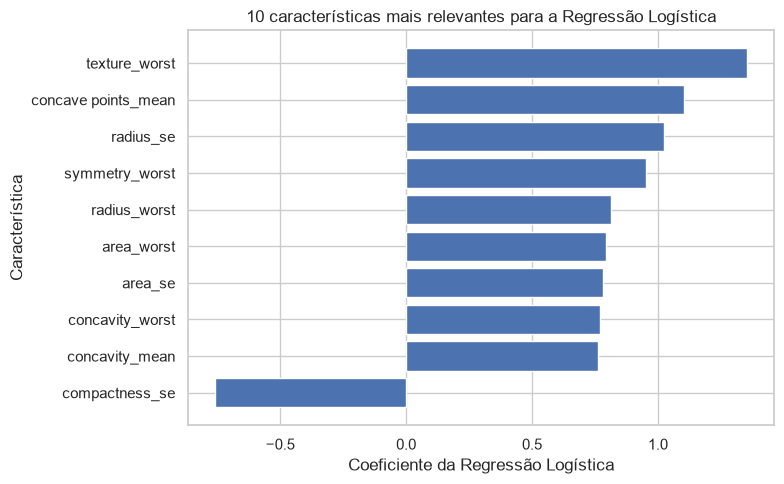

In [49]:
top10 = importancia_regressao.head(10).sort_values(
    "Importancia_absoluta"
)

plt.figure(figsize=(8, 5))
plt.barh(
    top10["Caracteristica"],
    top10["Coeficiente"]
)
plt.xlabel("Coeficiente da Regressão Logística")
plt.ylabel("Característica")
plt.title("10 características mais relevantes para a Regressão Logística")
plt.tight_layout()
plt.show()


## O que o modelo identificou

A análise dos coeficientes da **Regressão Logística** permite identificar quais características apresentaram maior influência relativa na classificação dos tumores dentro do modelo.

### Principais características

| # | Característica | Interpretação no modelo |
|---|---|---|
| 1 | `texture_worst` | Maior influência relativa entre as características analisadas |
| 2 | `concave points_mean` | Alta influência relativa |
| 3 | `radius_se` | Alta influência relativa |
| 4 | `symmetry_worst` | Alta influência relativa |
| 5 | `radius_worst` | Influência relevante |

---

## Como interpretar os coeficientes

> **Importante:** os coeficientes representam a influência das características na decisão do modelo. Eles não representam causalidade e não devem ser interpretados como uma conclusão médica.

### Coeficiente positivo

Um coeficiente **positivo** indica associação com o aumento da probabilidade estimada para a classe `M` (**maligno**), considerando a codificação utilizada pelo modelo.

### Coeficiente negativo

Um coeficiente **negativo** indica associação no sentido contrário à classe `M`, dentro do modelo.

---

## Principal resultado

A característica com maior coeficiente absoluto foi:

> **`texture_worst` — coeficiente: 1,355329**

Isso significa que, **dentro da Regressão Logística treinada neste conjunto de dados**, `texture_worst` foi a característica com maior influência relativa entre as variáveis analisadas.

---

## Limitação da interpretação

A importância dos coeficientes deve ser entendida como uma **interpretação do comportamento do modelo**, e não como uma relação causal.

Portanto:

- o modelo não está afirmando que uma característica **causa** malignidade;
- a análise não substitui avaliação médica;
- os resultados são específicos para o conjunto de dados utilizado;
- características correlacionadas podem influenciar conjuntamente os coeficientes.

---

### Conclusão

A análise dos coeficientes fornece uma forma interpretável de entender **quais características mais influenciaram as decisões da Regressão Logística** neste experimento.


# 12. Conclusão

A comparação dos modelos e a interpretação dos coeficientes estão nas seções anteriores. A discussão prática, a conclusão final e a auditoria dos requisitos ficam para a próxima etapa.
